In [ ]:


import pandas as pd
import numpy as np
import xgboost as xgb
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split


# Load the breast cancer dataset
data = load_breast_cancer()
df = pd.DataFrame(data.data, columns=data.feature_names)
df['target'] = data.target
df

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,0.1726,0.05623,...,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115,0
565,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,0.1752,0.05533,...,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637,0
566,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,0.1590,0.05648,...,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820,0
567,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,0.2397,0.07016,...,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400,0


In [38]:
X, y = data.data, data.target


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
# setting up model 1 using xgbclassifier for a classification model
model = xgb.XGBClassifier(
    n_estimators=100,      # Number of boosting rounds (trees)
    max_depth=4,           # Maximum depth of each tree
    learning_rate=0.1,     # Step size shrinkage to prevent overfitting
    random_state=42
)

In [39]:
model.fit(X_train, y_train)

,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,None
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [40]:
from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score

y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
print(f"Model Accuracy: {accuracy * 100:.2f}%")

# Perform cross-validation
cv_scores = cross_val_score(model, X_train, y_train, cv=5)
print(f"Cross-Validation Scores: {cv_scores}")
print(f"Mean CV Score: {cv_scores.mean() * 100:.2f}%")

Model Accuracy: 95.61%
Cross-Validation Scores: [0.96703297 0.94505495 0.98901099 0.95604396 0.93406593]
Mean CV Score: 95.82%


In [41]:
heart_disease_data = pd.read_csv("data/90 - heart-disease.csv")


X = heart_disease_data.drop("target", axis=1)
y = heart_disease_data["target"]


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)



In [42]:
model = xgb.XGBClassifier(
    n_estimators=100,      # Number of boosting rounds (trees)
    max_depth=4,           # Maximum depth of each tree
    learning_rate=0.1,     # Step size shrinkage to prevent overfitting
    random_state=42
)

model.fit(X_train, y_train)

,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,None
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [43]:
y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
print(f"Model Accuracy: {accuracy * 100:.2f}%")

Model Accuracy: 80.33%


In [44]:
model_score = model.score(X_test, y_pred)
print(f"Model Score: {model_score * 100:.2f}%")

Model Score: 100.00%


In [45]:
y_probs = model.predict_proba(X_test)
y_probs

array([[9.88658488e-01, 1.13415234e-02],
       [6.38895988e-01, 3.61104041e-01],
       [8.12884927e-01, 1.87115073e-01],
       [9.91028190e-01, 8.97182617e-03],
       [3.34075689e-02, 9.66592431e-01],
       [1.47784352e-02, 9.85221565e-01],
       [5.14030635e-01, 4.85969365e-01],
       [9.97284114e-01, 2.71589961e-03],
       [9.96841311e-01, 3.15868575e-03],
       [5.46766281e-01, 4.53233749e-01],
       [3.16509604e-02, 9.68349040e-01],
       [9.37573075e-01, 6.24269359e-02],
       [4.86446619e-02, 9.51355338e-01],
       [9.87238228e-01, 1.27617586e-02],
       [6.46471977e-03, 9.93535280e-01],
       [2.98964977e-03, 9.97010350e-01],
       [2.30461359e-03, 9.97695386e-01],
       [9.76658463e-01, 2.33415328e-02],
       [9.96626318e-01, 3.37366434e-03],
       [9.94272053e-01, 5.72796771e-03],
       [3.89882743e-01, 6.10117257e-01],
       [9.91967320e-01, 8.03268980e-03],
       [3.04225087e-02, 9.69577491e-01],
       [4.27516103e-02, 9.57248390e-01],
       [1.401590

In [46]:
from sklearn.metrics import roc_curve, auc
# Calculate fpr, tpr and thresholds

fpr, tpr, thresholds = roc_curve(y_test, y_probs[:, 1])
roc_auc = auc(fpr, tpr)

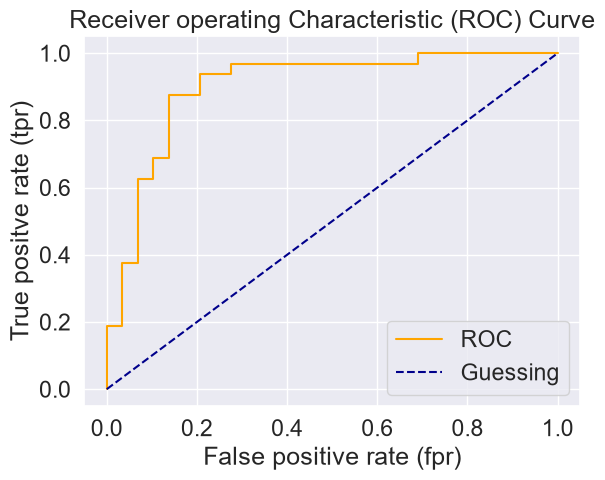

In [47]:
import matplotlib.pyplot as plt

def plot_roc_curve(fpr, tpr):
    """
    Plots a roc curve given the false positive rate and true positive rate of the model.
    """

    # Plot roc curve

    plt.plot(fpr, tpr, color="orange", label="ROC")

    # Plot a guessing curve

    plt.plot([0, 1], [0, 1], color="darkblue", label="Guessing", linestyle="--")

    # Customizing the plot

    plt.xlabel("False positive rate (fpr)")
    plt.ylabel("True positve rate (tpr)")
    plt.title("Receiver operating Characteristic (ROC) Curve")

    plt.legend()
    plt.show()


plot_roc_curve(fpr, tpr)

In [48]:
from sklearn.metrics import roc_auc_score

roc_auc = roc_auc_score(y_test, y_probs[:, 1])
roc_auc2 = auc(fpr, tpr)
roc_auc, roc_auc2

(0.9008620689655173, 0.9008620689655173)

In [49]:
fpr

array([0.        , 0.        , 0.        , 0.03448276, 0.03448276,
       0.06896552, 0.06896552, 0.10344828, 0.10344828, 0.13793103,
       0.13793103, 0.20689655, 0.20689655, 0.27586207, 0.27586207,
       0.68965517, 0.68965517, 1.        ])

In [50]:
tpr

array([0.     , 0.03125, 0.1875 , 0.1875 , 0.375  , 0.375  , 0.625  ,
       0.625  , 0.6875 , 0.6875 , 0.875  , 0.875  , 0.9375 , 0.9375 ,
       0.96875, 0.96875, 1.     , 1.     ])

In [51]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

pd.DataFrame(cm, index=["Actual Negative", "Actual Positive"], columns=["Predicted Negative", "Predicted Positive"])

# pd.crosstab(y_test, y_pred, rownames=["Actual Labels"], colnames=["Predicted Labels"])
# pd.crosstab(index=["Actual Labels"], columns=["Predicted Labels"])

,Predicted Negative,Predicted Positive
Actual Negative,25,4
Actual Positive,8,24


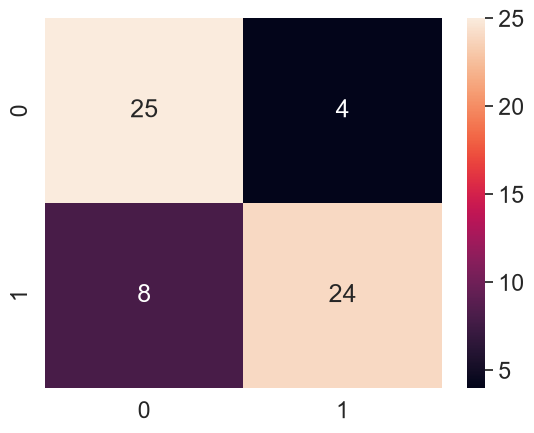

In [52]:
import seaborn as sns

sns.set_theme(font_scale=1.5)

sns.heatmap(cm, annot=True, fmt='d');

In [53]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.76      0.86      0.81        29
           1       0.86      0.75      0.80        32

    accuracy                           0.80        61
   macro avg       0.81      0.81      0.80        61
weighted avg       0.81      0.80      0.80        61



In [54]:
np.random.seed(42)

for i in range(100, 200, 10):


    print(f"Training model with {i} estimators...")
    model = xgb.XGBClassifier(
        n_estimators=i,      # Number of boosting rounds (trees)
        max_depth=4,
        learning_rate=0.1,     # Step size shrinkage to prevent overfitting
        random_state=42
    )

    model.fit(X_train, y_train)

    model_score = model.score(X_test, y_test)
    print(f"Model with {i} estimators achieved accuracy: {model_score * 100:.2f}%")

    cross_val_scores = np.mean(cross_val_score(model, X, y, cv=5, scoring='f1'))
    print(f"Cross-validation scores: {cross_val_scores * 100:.2f}%")

    print(" ")




Training model with 100 estimators...
Model with 100 estimators achieved accuracy: 80.33%
Cross-validation scores: 81.07%
 
Training model with 110 estimators...
Model with 110 estimators achieved accuracy: 80.33%
Cross-validation scores: 80.44%
 
Training model with 120 estimators...
Model with 120 estimators achieved accuracy: 81.97%
Cross-validation scores: 81.06%
 
Training model with 130 estimators...
Model with 130 estimators achieved accuracy: 80.33%
Cross-validation scores: 81.03%
 
Training model with 140 estimators...
Model with 140 estimators achieved accuracy: 80.33%
Cross-validation scores: 81.37%
 
Training model with 150 estimators...
Model with 150 estimators achieved accuracy: 80.33%
Cross-validation scores: 81.10%
 
Training model with 160 estimators...
Model with 160 estimators achieved accuracy: 78.69%
Cross-validation scores: 81.48%
 
Training model with 170 estimators...
Model with 170 estimators achieved accuracy: 80.33%
Cross-validation scores: 80.83%
 
Training

In [55]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [3, 4, 5],
    'learning_rate': [0.1, 0.2, 0.3]
}

grid = GridSearchCV(estimator=xgb.XGBClassifier(random_state=42), param_grid=param_grid, cv=5, scoring='accuracy', n_jobs=-1)


grid.fit(X, y)

print(f"Best parameters found: {grid.best_params_}")
print(f"Best cross-validation score: {grid.best_score_ * 100:.2f}%")

Best parameters found: {'learning_rate': 0.2, 'max_depth': 5, 'n_estimators': 300}
Best cross-validation score: 81.84%


In [56]:
np.random.seed(42)


diseases_true = np.zeros(1000)

diseases_true[0] = 1  # First patient has the disease

diseases_pred = np.zeros(1000)

pd.DataFrame(classification_report(diseases_true, diseases_pred, output_dict=True, zero_division=0)).T

,precision,recall,f1-score,support
0.0,0.999000,1.000,0.99950,999.000
1.0,0.000000,0.000,0.00000,1.000
accuracy,0.999000,0.999,0.99900,0.999
macro avg,0.499500,0.500,0.49975,1000.000
weighted avg,0.998001,0.999,0.99850,1000.000
